# Model 2 — Clean Evaluation Notebook (Readiness-Only EfficientNet-B0)

This notebook evaluates the **main readiness-only Model 2** using the saved Fold 3 predictions and checkpoint. It does not retrain the model.

It generates:
- Regression metrics for `R_seg` and `R_F1` (MAE, RMSE, R², Pearson correlation).
- Actual-vs-predicted plots and residual plots.
- Training/validation loss plots when compatible history columns are present.
- Binary AI-readiness metrics at a configurable threshold (default `0.70`), confusion matrices, ROC curves, and classification reports.
- Degradation-severity analyses and plots when the required metadata columns are available.
- Qualitative examples with original/degraded images and Grad-CAM for both outputs.
- CSV and PNG outputs saved to a dedicated results directory.

**Important:** the notebook intentionally uses `Models/EfficientNet_Rseg_RF1_ReadinessOnly/` and the dataset folder `AI_Readiness_Dataset (1)`. It does not use the hierarchical model's checkpoint or predictions.

In [1]:
# CELL 1 — Mount Drive, imports, paths, and configuration

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from scipy.stats import pearsonr, spearmanr

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import efficientnet_b0

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, ConfusionMatrixDisplay
)
from IPython.display import display

PROJECT_ROOT = "/content/drive/MyDrive/AI_Readiness_Project"
DATASET_ROOT = os.path.join(PROJECT_ROOT, "AI_Readiness_Dataset (1)")
MODEL_DIR = os.path.join(PROJECT_ROOT, "Models", "EfficientNet_Rseg_RF1_ReadinessOnly")

PREDICTIONS_FILE = os.path.join(MODEL_DIR, "fold3_test_predictions.csv")
METRICS_FILE = os.path.join(MODEL_DIR, "fold3_test_metrics.csv")
HISTORY_FILE = os.path.join(MODEL_DIR, "training_history.csv")
CHECKPOINT_PATH = os.path.join(MODEL_DIR, "checkpoints", "best_model.pth")
METADATA_FILE = os.path.join(DATASET_ROOT, "metadata.csv")
TARGET_FILE = os.path.join(DATASET_ROOT, "Targets", "AI_Readiness_Targets_CORRECTED.csv")

RESULTS_DIR = os.path.join(PROJECT_ROOT, "Results", "Model2_ReadinessOnly_Evaluation")
FIGURES_DIR = os.path.join(RESULTS_DIR, "Figures")
GRADCAM_DIR = os.path.join(RESULTS_DIR, "GradCAM")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(GRADCAM_DIR, exist_ok=True)

# Threshold for converting continuous readiness into binary labels.
THRESHOLD = 0.70

# Number of held-out examples for image/Grad-CAM figures.
N_QUALITATIVE_EXAMPLES = 5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for label, path in {
    "Predictions": PREDICTIONS_FILE,
    "Metadata": METADATA_FILE,
    "Checkpoint": CHECKPOINT_PATH,
}.items():
    print(f"{label}: {'FOUND' if os.path.isfile(path) else 'NOT FOUND'} — {path}")

if not os.path.isfile(PREDICTIONS_FILE):
    raise FileNotFoundError(f"Saved Fold 3 predictions not found: {PREDICTIONS_FILE}")
if not os.path.isfile(METADATA_FILE):
    raise FileNotFoundError(f"Metadata file not found: {METADATA_FILE}")

Mounted at /content/drive
Device: cpu
Predictions: FOUND — /content/drive/MyDrive/AI_Readiness_Project/Models/EfficientNet_Rseg_RF1_ReadinessOnly/fold3_test_predictions.csv
Metadata: FOUND — /content/drive/MyDrive/AI_Readiness_Project/AI_Readiness_Dataset (1)/metadata.csv
Checkpoint: FOUND — /content/drive/MyDrive/AI_Readiness_Project/Models/EfficientNet_Rseg_RF1_ReadinessOnly/checkpoints/best_model.pth


In [2]:
# CELL 2 — Load and validate Fold 3 predictions + metadata

pred_df = pd.read_csv(PREDICTIONS_FILE)
metadata = pd.read_csv(METADATA_FILE)

required_pred_cols = ["image_id", "R_seg_true", "R_seg_pred", "R_F1_true", "R_F1_pred"]
missing = [c for c in required_pred_cols if c not in pred_df.columns]
if missing:
    raise ValueError(
        f"Missing columns in {PREDICTIONS_FILE}: {missing}. "
        f"Available columns: {pred_df.columns.tolist()}"
    )

if "image_name" not in metadata.columns:
    raise ValueError(f"'image_name' missing from metadata. Columns: {metadata.columns.tolist()}")

def normalize_image_id(value):
    value = Path(str(value)).stem.strip()
    # Normalize numeric IDs like 7515, 07515, or 07515.png to 5-digit IDs.
    if value.isdigit():
        return value.zfill(5)
    return value

pred_df = pred_df.copy()
metadata = metadata.copy()
pred_df["image_id"] = pred_df["image_id"].map(normalize_image_id)
metadata["image_id"] = metadata["image_name"].map(normalize_image_id)

for col in required_pred_cols[1:]:
    pred_df[col] = pd.to_numeric(pred_df[col], errors="coerce")

before = len(pred_df)
pred_df = pred_df.dropna(subset=required_pred_cols[1:]).copy()
if len(pred_df) < before:
    print(f"Removed {before - len(pred_df)} prediction rows with missing/non-numeric target or prediction values.")

# Keep one metadata row per image ID to avoid duplicate joins.
metadata = metadata.drop_duplicates(subset=["image_id"], keep="first")
df = pred_df.merge(metadata, on="image_id", how="left", suffixes=("", "_metadata"))

if df.empty:
    raise ValueError("No rows available after loading the Fold 3 prediction file.")

print("Prediction rows:", len(pred_df))
print("Rows with matching metadata:", df["image_name"].notna().sum() if "image_name" in df.columns else "metadata merged")
print("Prediction columns:", pred_df.columns.tolist())
display(df[required_pred_cols].head())

Prediction rows: 2647
Rows with matching metadata: 2647
Prediction columns: ['image_id', 'R_seg_true', 'R_seg_pred', 'R_F1_true', 'R_F1_pred']


,image_id,R_seg_true,R_seg_pred,R_F1_true,R_F1_pred
0,05179,0.225047,0.770508,1.000000,0.880859
1,05180,0.465962,0.848633,1.000000,1.087891
2,05181,0.676478,0.648438,0.533333,0.556641
3,05182,0.474811,0.593750,0.880000,0.883789
4,05183,0.880937,0.749023,0.000000,1.152344


In [3]:
# CELL 3 — Regression metrics for the two readiness outputs

metric_rows = []

for target in ["R_seg", "R_F1"]:
    y_true = df[f"{target}_true"].to_numpy(dtype=float)
    y_pred = df[f"{target}_pred"].to_numpy(dtype=float)
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[valid], y_pred[valid]

    if len(y_true) == 0:
        continue

    pearson_r = pearsonr(y_true, y_pred).statistic if len(y_true) > 1 and np.std(y_true) > 0 and np.std(y_pred) > 0 else np.nan
    spearman_r = spearmanr(y_true, y_pred).statistic if len(y_true) > 1 else np.nan

    metric_rows.append({
        "Target": target,
        "N": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred) if len(y_true) > 1 else np.nan,
        "Pearson_r": pearson_r,
        "Spearman_r": spearman_r,
        "Bias_mean_pred_minus_true": float(np.mean(y_pred - y_true)),
    })

regression_metrics = pd.DataFrame(metric_rows)
display(regression_metrics.round(5))

regression_metrics.to_csv(
    os.path.join(RESULTS_DIR, "regression_metrics.csv"), index=False
)
print("Saved:", os.path.join(RESULTS_DIR, "regression_metrics.csv"))

,Target,N,MAE,RMSE,R2,Pearson_r,Spearman_r,Bias_mean_pred_minus_true
0,R_seg,2647,0.17548,0.23439,0.24818,0.51528,0.52106,-0.00743
1,R_F1,2647,0.29705,0.37529,0.17885,0.45575,0.35472,0.00064


Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/regression_metrics.csv


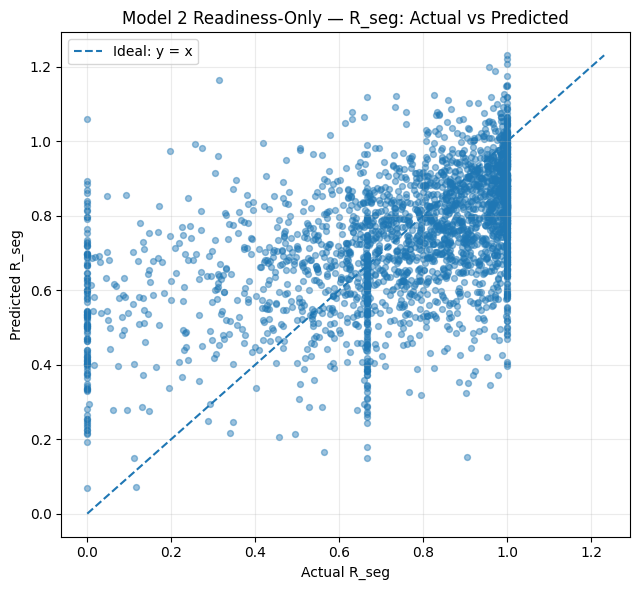

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_seg_actual_vs_predicted.png


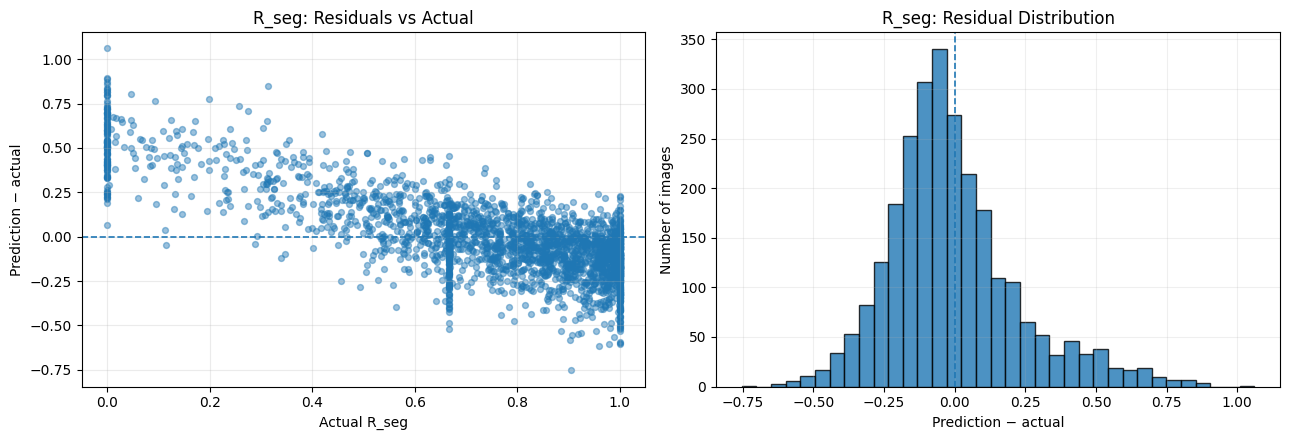

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_seg_residual_diagnostics.png


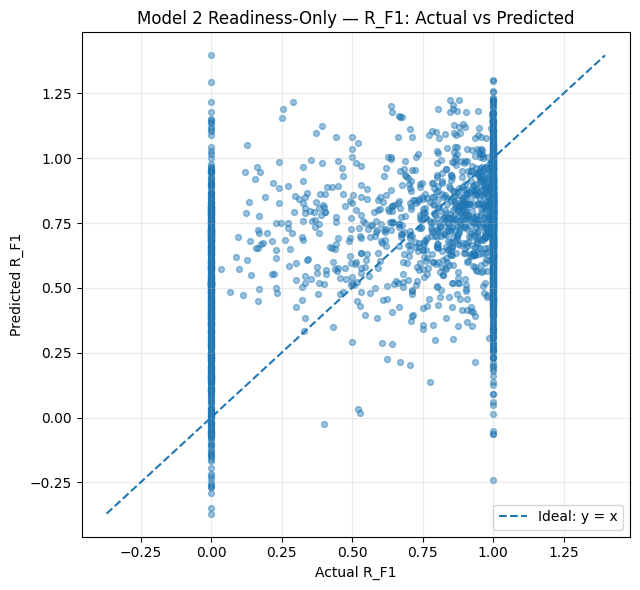

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_F1_actual_vs_predicted.png


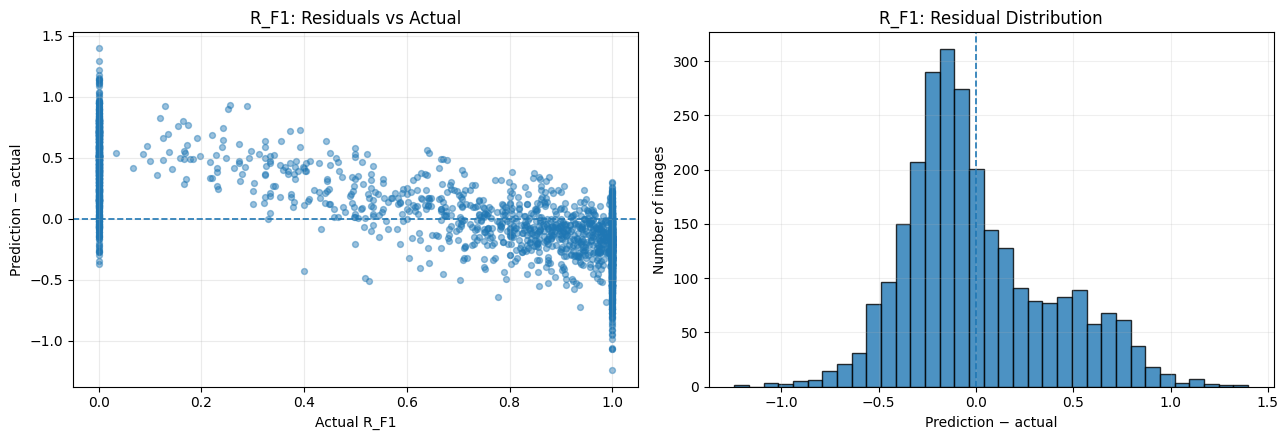

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_F1_residual_diagnostics.png


In [4]:
# CELL 4 — Actual-vs-predicted plots and residual diagnostics

for target in ["R_seg", "R_F1"]:
    y_true = df[f"{target}_true"].to_numpy(dtype=float)
    y_pred = df[f"{target}_pred"].to_numpy(dtype=float)
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[valid], y_pred[valid]
    residuals = y_pred - y_true

    # Actual vs predicted
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.scatter(y_true, y_pred, alpha=0.45, s=18)
    low = min(float(y_true.min()), float(y_pred.min()))
    high = max(float(y_true.max()), float(y_pred.max()))
    ax.plot([low, high], [low, high], linestyle="--", linewidth=1.5, label="Ideal: y = x")
    ax.set_xlabel(f"Actual {target}")
    ax.set_ylabel(f"Predicted {target}")
    ax.set_title(f"Model 2 Readiness-Only — {target}: Actual vs Predicted")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    out = os.path.join(FIGURES_DIR, f"{target}_actual_vs_predicted.png")
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", out)

    # Residual vs actual and residual distribution
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].scatter(y_true, residuals, alpha=0.45, s=18)
    axes[0].axhline(0, linestyle="--", linewidth=1.2)
    axes[0].set_xlabel(f"Actual {target}")
    axes[0].set_ylabel("Prediction − actual")
    axes[0].set_title(f"{target}: Residuals vs Actual")
    axes[0].grid(alpha=0.25)

    axes[1].hist(residuals, bins=35, edgecolor="black", alpha=0.8)
    axes[1].axvline(0, linestyle="--", linewidth=1.2)
    axes[1].set_xlabel("Prediction − actual")
    axes[1].set_ylabel("Number of images")
    axes[1].set_title(f"{target}: Residual Distribution")
    axes[1].grid(alpha=0.2)

    fig.tight_layout()
    out = os.path.join(FIGURES_DIR, f"{target}_residual_diagnostics.png")
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", out)

PROPOSED MODEL — READINESS LOSS CURVES


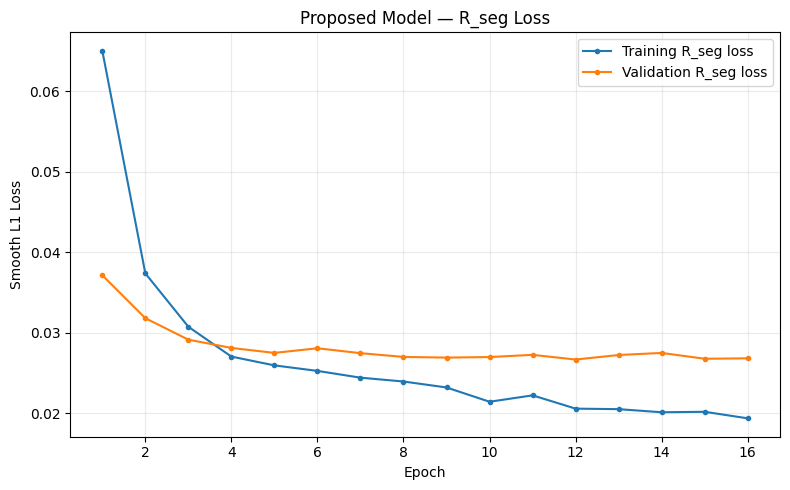

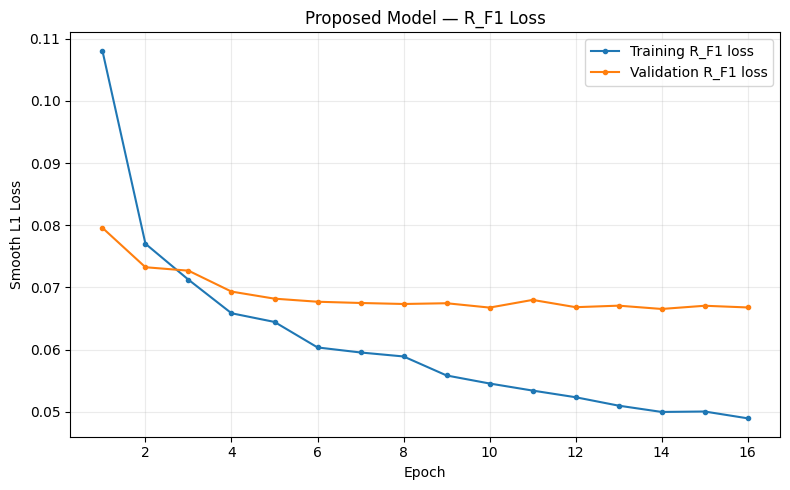


✓ Readiness loss plots saved


In [12]:

print("=" * 80)
print("PROPOSED MODEL — READINESS LOSS CURVES")
print("=" * 80)

history_path = os.path.join(
    PROJECT_ROOT,
    "Models",
    "EfficientNet_Rseg_RF1_Hierarchical",
    "training_history.csv"
)

h = pd.read_csv(
    history_path
)

# Detect column names
if "train_R_seg" in h.columns:

    train_rseg = "train_R_seg"
    train_rf1 = "train_R_F1"
    val_rseg = "val_R_seg"
    val_rf1 = "val_R_F1"

else:

    train_rseg = "train_R_seg_loss"
    train_rf1 = "train_R_F1_loss"
    val_rseg = "val_R_seg_loss"
    val_rf1 = "val_R_F1_loss"


# ============================================================
# R_SEG
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    h["epoch"],
    h[train_rseg],
    marker="o",
    markersize=3,
    label="Training R_seg loss"
)

plt.plot(
    h["epoch"],
    h[val_rseg],
    marker="o",
    markersize=3,
    label="Validation R_seg loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Smooth L1 Loss"
)

plt.title(
    "Proposed Model — R_seg Loss"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

path = os.path.join(
    RESULTS_DIR,
    "proposed_Rseg_loss.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# R_F1
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    h["epoch"],
    h[train_rf1],
    marker="o",
    markersize=3,
    label="Training R_F1 loss"
)

plt.plot(
    h["epoch"],
    h[val_rf1],
    marker="o",
    markersize=3,
    label="Validation R_F1 loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Smooth L1 Loss"
)

plt.title(
    "Proposed Model — R_F1 Loss"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

path = os.path.join(
    RESULTS_DIR,
    "proposed_RF1_loss.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    "\n✓ Readiness loss plots saved"
)

print("=" * 80)

Binary threshold: 0.70 (score >= threshold is AI-ready)

Segmentation readiness (R_seg)
              precision    recall  f1-score   support

Not AI-ready     0.6020    0.6633    0.6312       903
    AI-ready     0.8160    0.7729    0.7939      1744

    accuracy                         0.7355      2647
   macro avg     0.7090    0.7181    0.7125      2647
weighted avg     0.7430    0.7355    0.7384      2647



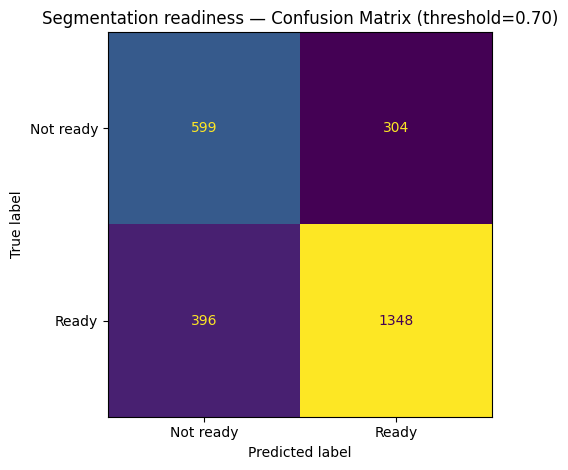

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_seg_confusion_matrix_thr_0.70.png


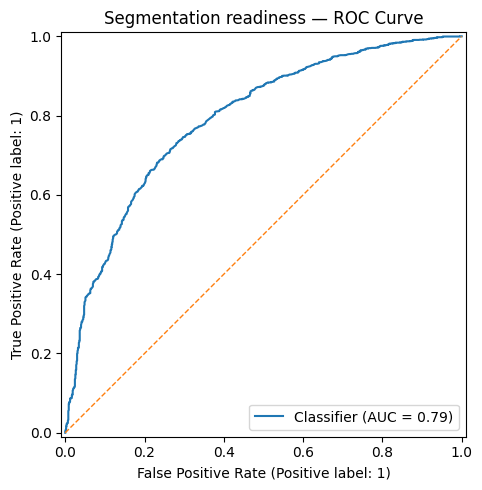

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_seg_roc_curve.png

Classification readiness (R_F1)
              precision    recall  f1-score   support

Not AI-ready     0.4895    0.6599    0.5621       885
    AI-ready     0.7930    0.6544    0.7170      1762

    accuracy                         0.6562      2647
   macro avg     0.6413    0.6571    0.6396      2647
weighted avg     0.6915    0.6562    0.6652      2647



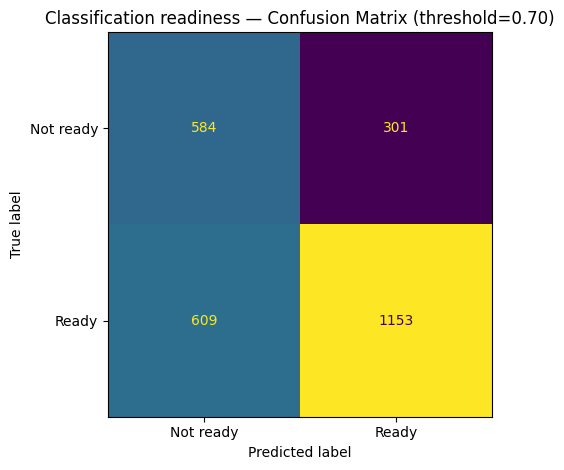

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_F1_confusion_matrix_thr_0.70.png


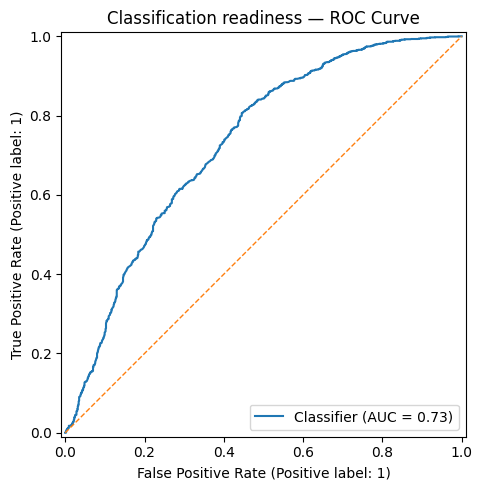

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_F1_roc_curve.png


,Task,Target,Threshold,N,Accuracy,Precision,Recall,F1,ROC_AUC,TN,FP,FN,TP
0,Segmentation readiness,R_seg,0.7,2647,0.7355,0.816,0.7729,0.7939,0.7915,599,304,396,1348
1,Classification readiness,R_F1,0.7,2647,0.6562,0.793,0.6544,0.7170,0.7288,584,301,609,1153


Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/binary_readiness_metrics.csv


In [6]:
# CELL 6 — Binary readiness evaluation at the chosen threshold

print(f"Binary threshold: {THRESHOLD:.2f} (score >= threshold is AI-ready)")

binary_rows = []
binary_arrays = {}

for target, label in [("R_seg", "Segmentation readiness"), ("R_F1", "Classification readiness")]:
    y_true_score = df[f"{target}_true"].to_numpy(dtype=float)
    y_pred_score = df[f"{target}_pred"].to_numpy(dtype=float)
    valid = np.isfinite(y_true_score) & np.isfinite(y_pred_score)
    y_true_score, y_pred_score = y_true_score[valid], y_pred_score[valid]

    y_true = (y_true_score >= THRESHOLD).astype(int)
    y_pred = (y_pred_score >= THRESHOLD).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    auc = np.nan
    if len(np.unique(y_true)) == 2:
        auc = roc_auc_score(y_true, y_pred_score)

    binary_rows.append({
        "Task": label,
        "Target": target,
        "Threshold": THRESHOLD,
        "N": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": auc,
        "TN": int(cm[0, 0]), "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]), "TP": int(cm[1, 1]),
    })
    binary_arrays[target] = (y_true, y_pred, y_pred_score, cm)

    print(f"\n{label} ({target})")
    print(classification_report(
        y_true, y_pred, labels=[0, 1],
        target_names=["Not AI-ready", "AI-ready"],
        digits=4, zero_division=0
    ))

    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not ready", "Ready"]
    ).plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"{label} — Confusion Matrix (threshold={THRESHOLD:.2f})")
    fig.tight_layout()
    out = os.path.join(FIGURES_DIR, f"{target}_confusion_matrix_thr_{THRESHOLD:.2f}.png")
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", out)

    if len(np.unique(y_true)) == 2:
        fig, ax = plt.subplots(figsize=(6, 5))
        RocCurveDisplay.from_predictions(y_true, y_pred_score, ax=ax)
        ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
        ax.set_title(f"{label} — ROC Curve")
        fig.tight_layout()
        out = os.path.join(FIGURES_DIR, f"{target}_roc_curve.png")
        fig.savefig(out, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        print("Saved:", out)

binary_metrics = pd.DataFrame(binary_rows)
display(binary_metrics.round(4))
binary_metrics.to_csv(os.path.join(RESULTS_DIR, "binary_readiness_metrics.csv"), index=False)
print("Saved:", os.path.join(RESULTS_DIR, "binary_readiness_metrics.csv"))

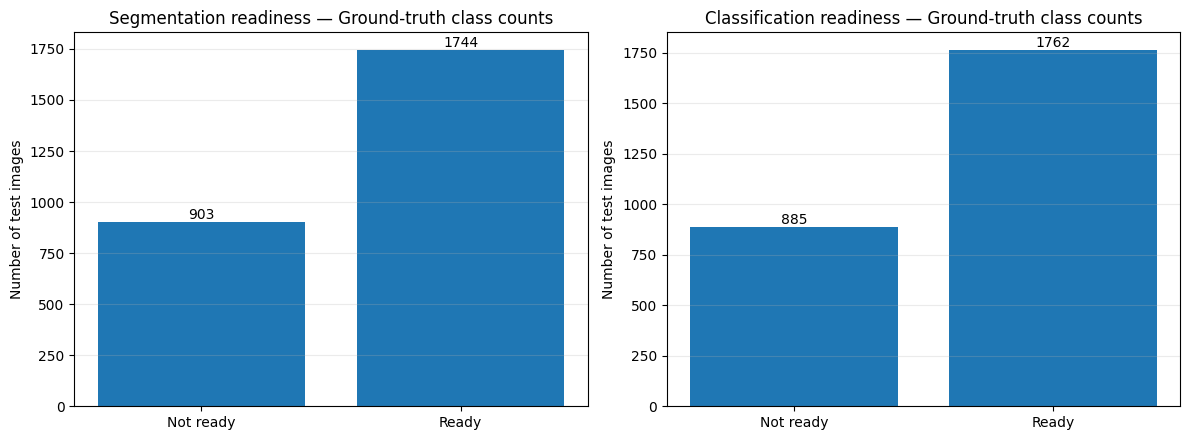

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/ground_truth_class_distribution_thr_0.70.png


,Threshold,Task,Accuracy,Precision,Recall,F1
0,0.5,Segmentation readiness,0.8455,0.8829,0.9436,0.9123
1,0.5,Classification readiness,0.7677,0.8003,0.8996,0.8471
2,0.6,Segmentation readiness,0.7847,0.8628,0.8669,0.8649
3,0.6,Classification readiness,0.7397,0.8109,0.8149,0.8129
4,0.7,Segmentation readiness,0.7355,0.8160,0.7729,0.7939
5,0.7,Classification readiness,0.6562,0.7930,0.6544,0.7170
6,0.8,Segmentation readiness,0.6902,0.7966,0.5819,0.6725
7,0.8,Classification readiness,0.5803,0.7868,0.4475,0.5705
8,0.9,Segmentation readiness,0.6895,0.7116,0.3304,0.4513
9,0.9,Classification readiness,0.5240,0.7088,0.2275,0.3444


Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/threshold_sensitivity.csv


In [7]:
# CELL 7 — Readiness class distributions and threshold sensitivity

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, target, title in [
    (axes[0], "R_seg", "Segmentation readiness"),
    (axes[1], "R_F1", "Classification readiness")
]:
    y_true = (df[f"{target}_true"] >= THRESHOLD).astype(int)
    counts = y_true.value_counts().reindex([0, 1], fill_value=0)
    ax.bar(["Not ready", "Ready"], counts.values)
    ax.set_title(f"{title} — Ground-truth class counts")
    ax.set_ylabel("Number of test images")
    ax.grid(axis="y", alpha=0.25)
    for j, v in enumerate(counts.values):
        ax.text(j, v, str(int(v)), ha="center", va="bottom")

fig.tight_layout()
out = os.path.join(FIGURES_DIR, f"ground_truth_class_distribution_thr_{THRESHOLD:.2f}.png")
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", out)

# Threshold sensitivity table (binary accuracy/F1 at multiple thresholds).
threshold_rows = []
for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    for target, label in [("R_seg", "Segmentation readiness"), ("R_F1", "Classification readiness")]:
        true_score = df[f"{target}_true"].to_numpy(dtype=float)
        pred_score = df[f"{target}_pred"].to_numpy(dtype=float)
        valid = np.isfinite(true_score) & np.isfinite(pred_score)
        y_true = (true_score[valid] >= threshold).astype(int)
        y_pred = (pred_score[valid] >= threshold).astype(int)
        threshold_rows.append({
            "Threshold": threshold,
            "Task": label,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0),
        })

threshold_sensitivity = pd.DataFrame(threshold_rows)
display(threshold_sensitivity.round(4))
threshold_sensitivity.to_csv(os.path.join(RESULTS_DIR, "threshold_sensitivity.csv"), index=False)
print("Saved:", os.path.join(RESULTS_DIR, "threshold_sensitivity.csv"))

,Degradation,Severity column,Measure,N,Pearson_r,Mean severity,Mean score
0,Blur,blur_score,R_seg_true,1054,-0.0947,12.0019,0.7317
1,Blur,blur_score,R_F1_true,1054,-0.0418,12.0019,0.6755
2,Blur,blur_score,R_seg_pred,1054,-0.0852,12.0019,0.7251
3,Blur,blur_score,R_F1_pred,1054,-0.0342,12.0019,0.6696
4,Motion blur,motion_score,R_seg_true,1054,-0.2306,11.3846,0.6925
5,Motion blur,motion_score,R_F1_true,1054,-0.1707,11.3846,0.6154
6,Motion blur,motion_score,R_seg_pred,1054,-0.2633,11.3846,0.6963
7,Motion blur,motion_score,R_F1_pred,1054,-0.1831,11.3846,0.6540
8,Brightness,brightness_score,R_seg_true,1068,-0.0199,6.1835,0.7443
9,Brightness,brightness_score,R_F1_true,1068,-0.0277,6.1835,0.6738


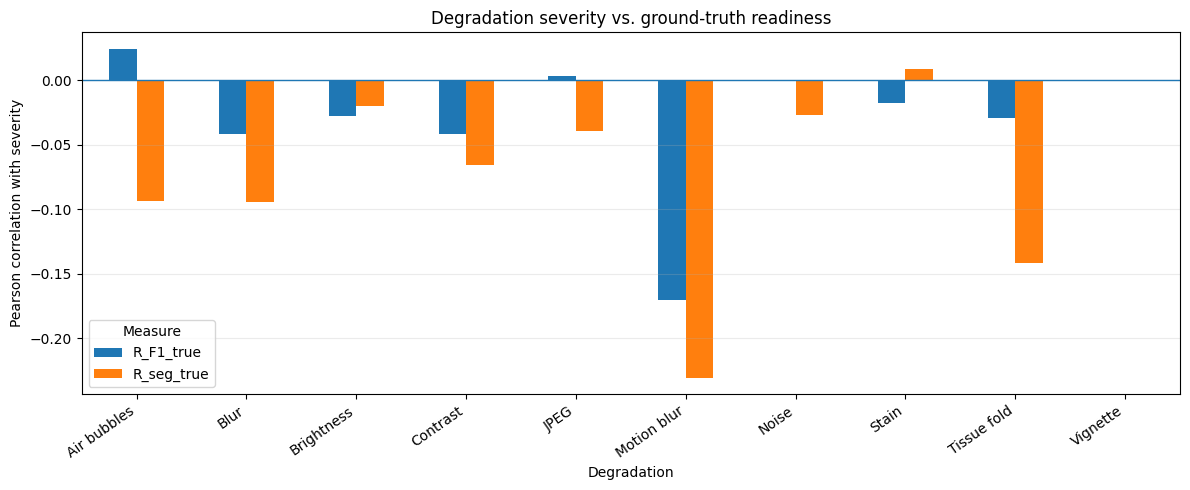

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/degradation_severity_correlations.png


In [8]:
# CELL 8 — Degradation presence/severity analysis (runs only for available columns)

# These columns are based on the dataset's metadata schema. Missing degradation
# columns are skipped with a message rather than causing the evaluation to fail.
degradation_specs = {
    "Blur": ("blur", "blur_score"),
    "Motion blur": ("motion_blur", "motion_score"),
    "Brightness": ("brightness", "brightness_score"),
    "Contrast": ("contrast", "contrast_score"),
    "Noise": ("noise", "noise_score"),
    "JPEG": ("jpeg", "jpeg_score"),
    "Stain": ("stain", "stain_score"),
    "Tissue fold": ("tissue_fold", "tissue_score"),
    "Air bubbles": ("air_bubbles", "bubble_score"),
    "Vignette": ("vignette", "vignette_score"),
}

severity_rows = []
for label, (presence_col, severity_col) in degradation_specs.items():
    if presence_col not in df.columns or severity_col not in df.columns:
        print(f"Skipping {label}: missing {presence_col!r} or {severity_col!r} in metadata.")
        continue

    subset = df[pd.to_numeric(df[presence_col], errors="coerce") == 1].copy()
    if subset.empty:
        print(f"Skipping {label}: no images marked with this degradation.")
        continue

    severity = pd.to_numeric(subset[severity_col], errors="coerce")
    for target in ["R_seg_true", "R_F1_true", "R_seg_pred", "R_F1_pred"]:
        subset[target] = pd.to_numeric(subset[target], errors="coerce")

    for target in ["R_seg_true", "R_F1_true", "R_seg_pred", "R_F1_pred"]:
        valid = severity.notna() & subset[target].notna()
        x = severity[valid].to_numpy(dtype=float)
        y = subset.loc[valid, target].to_numpy(dtype=float)
        corr = pearsonr(x, y).statistic if len(x) >= 3 and np.std(x) > 0 and np.std(y) > 0 else np.nan
        severity_rows.append({
            "Degradation": label,
            "Severity column": severity_col,
            "Measure": target,
            "N": len(x),
            "Pearson_r": corr,
            "Mean severity": float(np.mean(x)) if len(x) else np.nan,
            "Mean score": float(np.mean(y)) if len(y) else np.nan,
        })

severity_results = pd.DataFrame(severity_rows)
if not severity_results.empty:
    display(severity_results.round(4))
    severity_results.to_csv(os.path.join(RESULTS_DIR, "degradation_severity_correlations.csv"), index=False)

    plot_data = severity_results[severity_results["Measure"].isin(["R_seg_true", "R_F1_true"])].copy()
    if not plot_data.empty:
        pivot = plot_data.pivot(index="Degradation", columns="Measure", values="Pearson_r")
        ax = pivot.plot(kind="bar", figsize=(12, 5))
        ax.axhline(0, linewidth=1)
        ax.set_ylabel("Pearson correlation with severity")
        ax.set_title("Degradation severity vs. ground-truth readiness")
        ax.grid(axis="y", alpha=0.25)
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        out = os.path.join(FIGURES_DIR, "degradation_severity_correlations.png")
        plt.savefig(out, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", out)
else:
    print("No degradation severity analysis could be produced from available metadata columns.")

In [9]:
# CELL 9 — Load the readiness-only model checkpoint for Grad-CAM

if not os.path.isfile(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Model checkpoint not found: {CHECKPOINT_PATH}. "
        "Grad-CAM requires the trained model weights."
    )

class ReadinessOnlyEfficientNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = efficientnet_b0(weights=None)
        feature_dim = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()
        self.head = nn.Sequential(
            nn.Linear(feature_dim, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(),
            nn.Dropout(0.25),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.head(self.backbone(x))

model = ReadinessOnlyEfficientNet().to(DEVICE)
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
state = checkpoint.get("model_state", checkpoint)
model.load_state_dict(state, strict=True)
model.eval()

print("Readiness-only checkpoint loaded.")
print("Checkpoint epoch:", checkpoint.get("epoch", "not recorded"))
print("Checkpoint stage:", checkpoint.get("stage", "not recorded"))

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def preprocess_image(pil_image):
    pil_image = pil_image.resize((224, 224), Image.Resampling.BILINEAR)
    arr = np.asarray(pil_image).astype(np.float32) / 255.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1)
    tensor = (tensor - MEAN) / STD
    return tensor.unsqueeze(0).to(DEVICE)

def resolve_image_path(path):
    if pd.isna(path):
        return None
    path = str(path)
    candidates = [
        path,
        os.path.join(DATASET_ROOT, path),
        os.path.join(PROJECT_ROOT, path),
    ]
    for candidate in candidates:
        if os.path.isfile(candidate):
            return candidate
    return None

if "original_path" not in df.columns or "degraded_path" not in df.columns:
    raise ValueError("Metadata merge did not provide original_path and degraded_path columns.")

df["original_file"] = df["original_path"].apply(resolve_image_path)
df["degraded_file"] = df["degraded_path"].apply(resolve_image_path)

print("Rows with original image:", int(df["original_file"].notna().sum()))
print("Rows with degraded image:", int(df["degraded_file"].notna().sum()))

Readiness-only checkpoint loaded.
Checkpoint epoch: 15
Checkpoint stage: 3
Rows with original image: 2647
Rows with degraded image: 2647


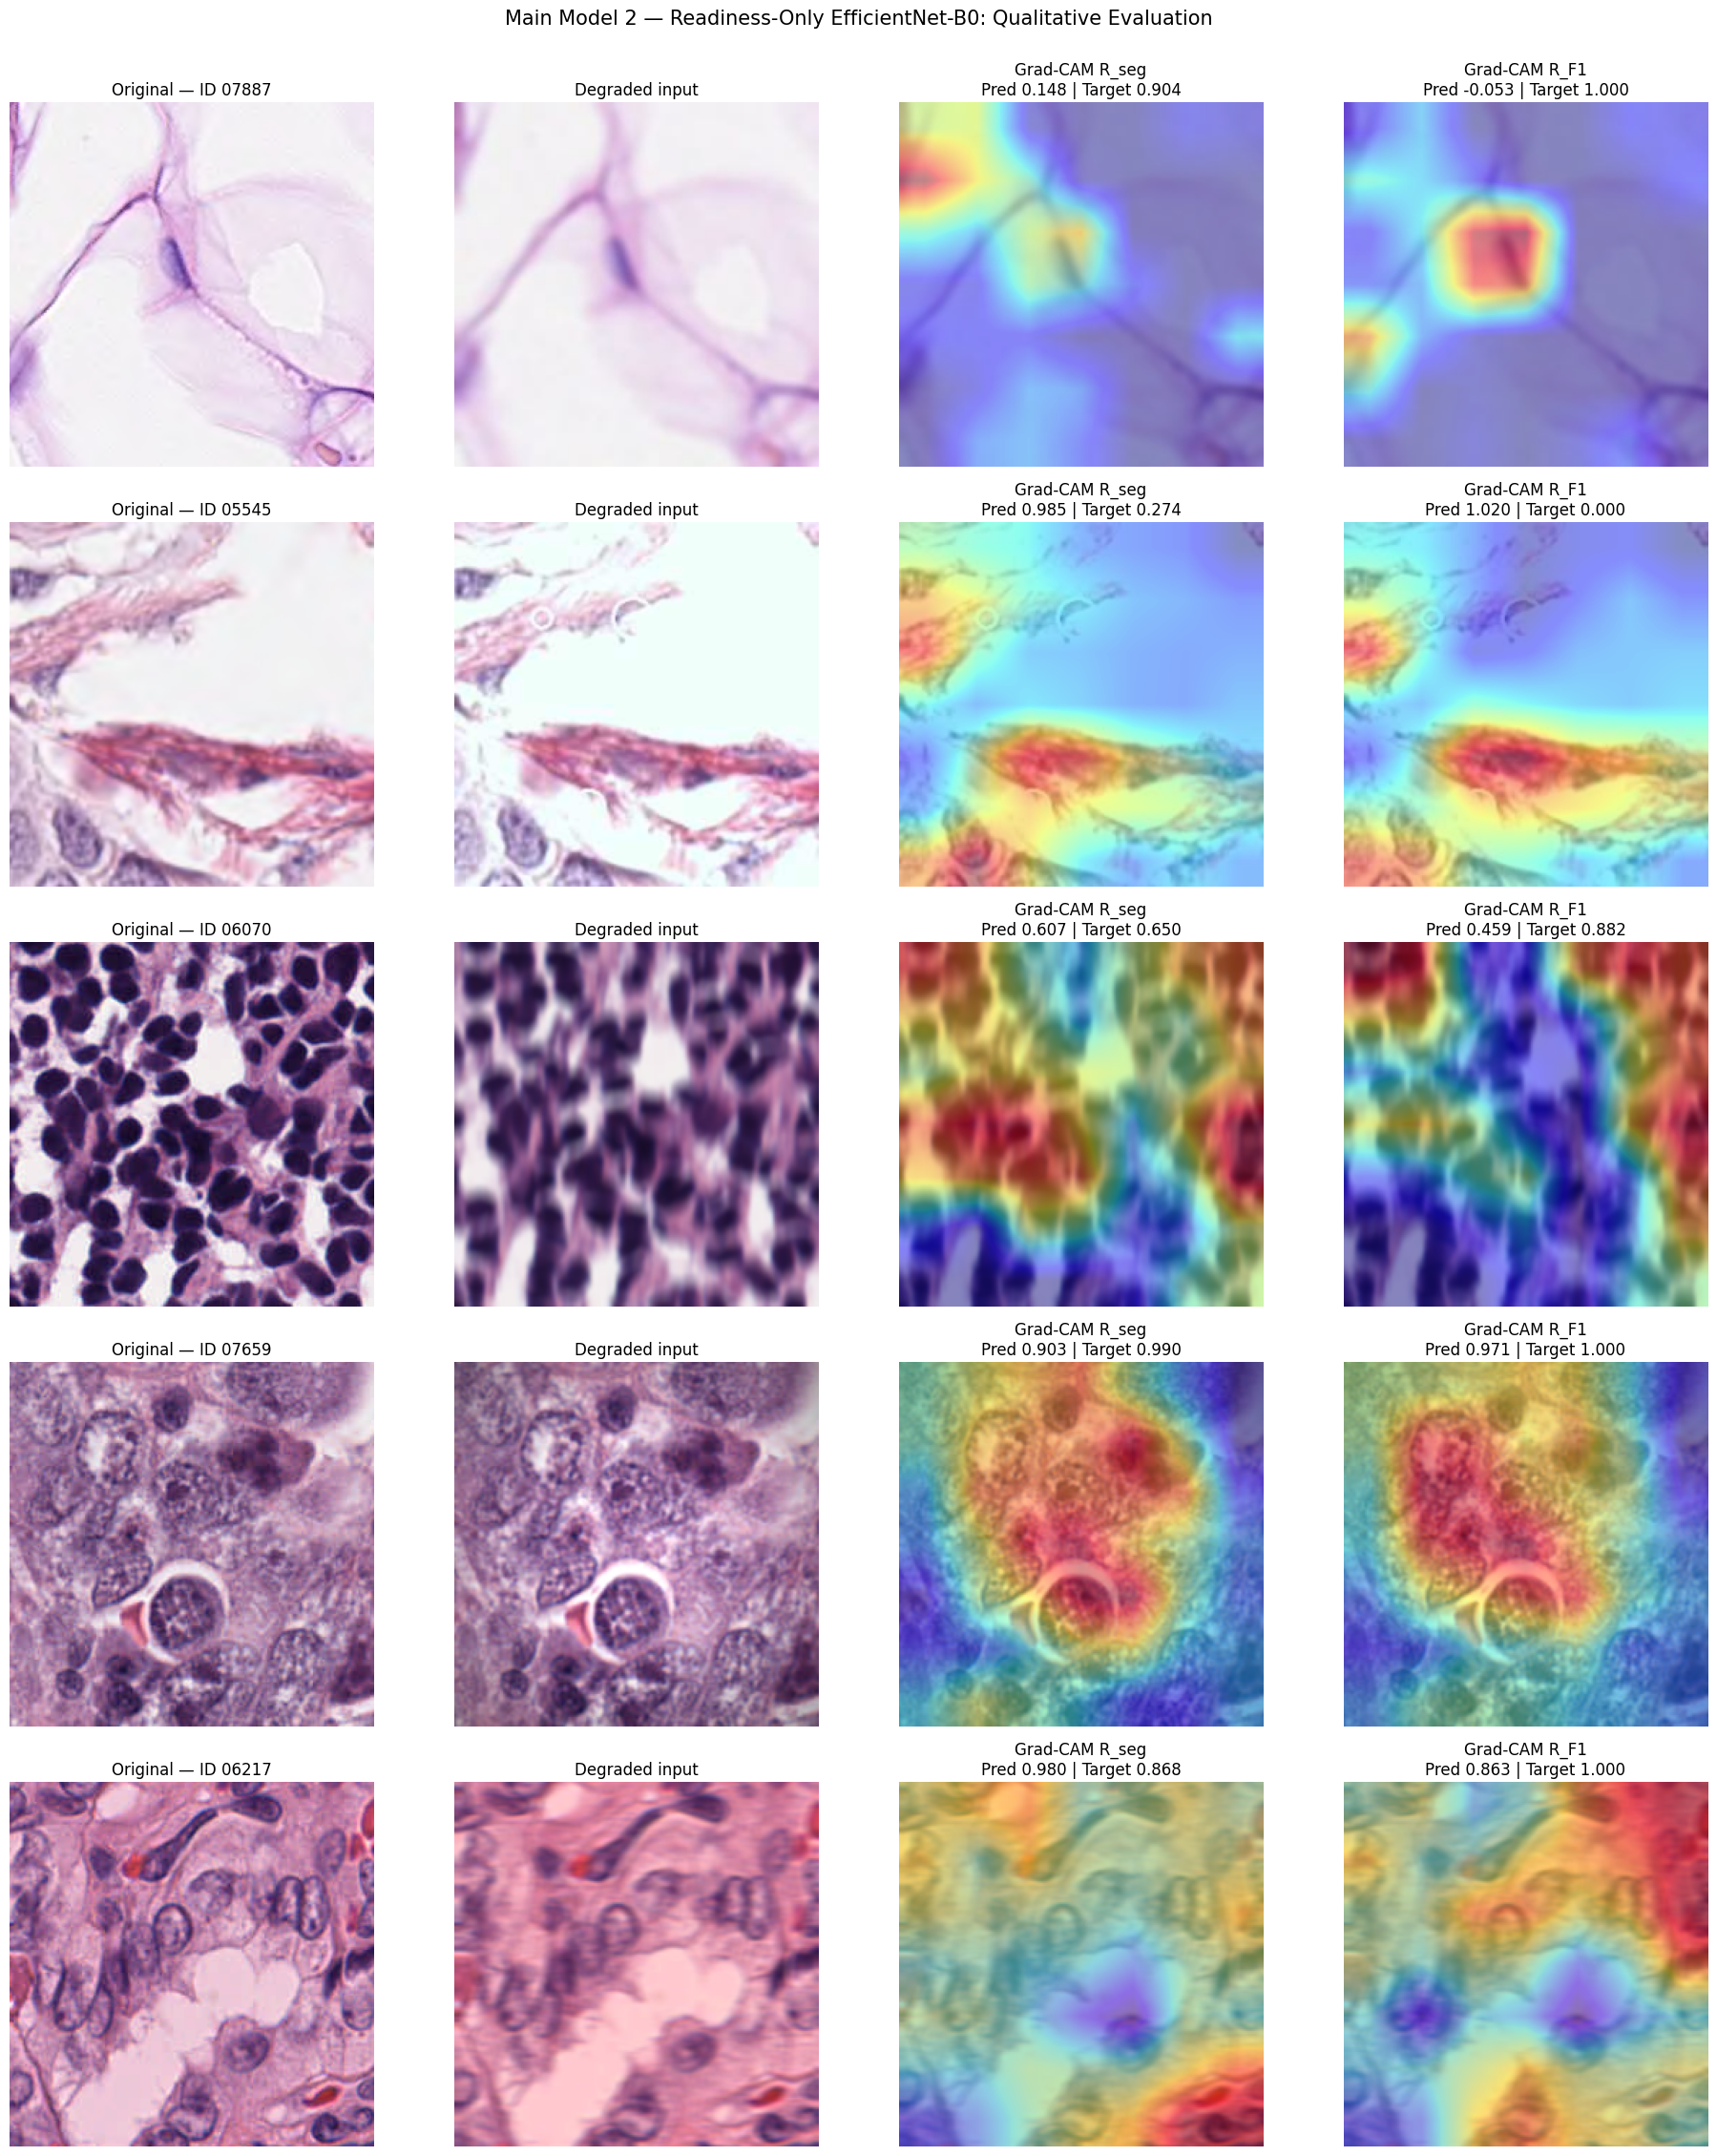

Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/five_qualitative_gradcam_examples.png


,image_id,R_seg_true,R_seg_pred_from_checkpoint,R_seg_pred_from_saved_csv,R_F1_true,R_F1_pred_from_checkpoint,R_F1_pred_from_saved_csv,degraded_path
0,07887,0.9043,0.1478,0.1509,1.0000,-0.0529,-0.0533,/content/drive/MyDrive/AI_Readiness_Project/AI...
1,05545,0.2740,0.9850,0.9834,0.0000,1.0198,1.0166,/content/drive/MyDrive/AI_Readiness_Project/AI...
2,06070,0.6496,0.6072,0.6060,0.8817,0.4594,0.4573,/content/drive/MyDrive/AI_Readiness_Project/AI...
3,07659,0.9896,0.9032,0.9019,1.0000,0.9712,0.9712,/content/drive/MyDrive/AI_Readiness_Project/AI...
4,06217,0.8681,0.9802,0.9805,1.0000,0.8625,0.8628,/content/drive/MyDrive/AI_Readiness_Project/AI...


Saved: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/qualitative_gradcam_examples.csv


In [10]:
# CELL 10 — Five qualitative test cases: images, predictions, and Grad-CAM

qual_df = df.dropna(subset=["original_file", "degraded_file"]).copy()
if qual_df.empty:
    raise FileNotFoundError(
        "No image paths could be resolved. Inspect metadata original_path/degraded_path "
        "and update resolve_image_path() for your storage layout."
    )

# Select five diverse examples: largest total absolute error first, then fill with random cases.
qual_df["_combined_error"] = (
    (qual_df["R_seg_true"] - qual_df["R_seg_pred"]).abs()
    + (qual_df["R_F1_true"] - qual_df["R_F1_pred"]).abs()
)
n = min(N_QUALITATIVE_EXAMPLES, len(qual_df))
worst_n = min(max(1, n // 2), n)
chosen = qual_df.nlargest(worst_n, "_combined_error")
remaining = qual_df.drop(index=chosen.index)
if len(chosen) < n and not remaining.empty:
    chosen = pd.concat([
        chosen,
        remaining.sample(n=min(n - len(chosen), len(remaining)), random_state=42)
    ])
chosen = chosen.drop_duplicates("image_id").head(n).reset_index(drop=True)

target_layer = model.backbone.features[-1]
qualitative_rows = []

fig, axes = plt.subplots(len(chosen), 4, figsize=(19, 4.5 * len(chosen)), squeeze=False)

for i, (_, row) in enumerate(chosen.iterrows()):
    image_id = str(row["image_id"]).zfill(5)
    original_image = Image.open(row["original_file"]).convert("RGB")
    degraded_image = Image.open(row["degraded_file"]).convert("RGB")
    input_tensor = preprocess_image(degraded_image)
    display_degraded = np.asarray(degraded_image.resize((224, 224), Image.Resampling.BILINEAR))

    activations = {}
    gradients = {}

    def _forward_hook(module, inputs, output):
        activations["feature"] = output
        output.register_hook(lambda grad: gradients.__setitem__("feature", grad))

    handle = target_layer.register_forward_hook(_forward_hook)
    try:
        model.zero_grad(set_to_none=True)
        outputs = model(input_tensor)[0]
        prediction = outputs.detach().cpu().numpy()
        cams = {}

        for output_index, output_name in [(0, "R_seg"), (1, "R_F1")]:
            model.zero_grad(set_to_none=True)
            gradients.pop("feature", None)
            outputs[output_index].backward(retain_graph=(output_index == 0))

            feature = activations["feature"].detach()
            grad = gradients["feature"].detach()
            weights = grad.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu((weights * feature).sum(dim=1, keepdim=True))
            cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
            cam = cam.detach().cpu().numpy()
            if cam.max() > cam.min():
                cam = (cam - cam.min()) / (cam.max() - cam.min())
            else:
                cam = np.zeros_like(cam)
            cams[output_name] = cam
    finally:
        handle.remove()

    pred_seg, pred_f1 = float(prediction[0]), float(prediction[1])
    true_seg, true_f1 = float(row["R_seg_true"]), float(row["R_F1_true"])

    axes[i, 0].imshow(original_image)
    axes[i, 0].set_title(f"Original — ID {image_id}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(display_degraded)
    axes[i, 1].set_title("Degraded input")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(display_degraded)
    axes[i, 2].imshow(cams["R_seg"], cmap="jet", alpha=0.45, vmin=0, vmax=1)
    axes[i, 2].set_title(f"Grad-CAM R_seg\nPred {pred_seg:.3f} | Target {true_seg:.3f}")
    axes[i, 2].axis("off")

    axes[i, 3].imshow(display_degraded)
    axes[i, 3].imshow(cams["R_F1"], cmap="jet", alpha=0.45, vmin=0, vmax=1)
    axes[i, 3].set_title(f"Grad-CAM R_F1\nPred {pred_f1:.3f} | Target {true_f1:.3f}")
    axes[i, 3].axis("off")

    qualitative_rows.append({
        "image_id": image_id,
        "R_seg_true": true_seg,
        "R_seg_pred_from_checkpoint": pred_seg,
        "R_seg_pred_from_saved_csv": float(row["R_seg_pred"]),
        "R_F1_true": true_f1,
        "R_F1_pred_from_checkpoint": pred_f1,
        "R_F1_pred_from_saved_csv": float(row["R_F1_pred"]),
        "degraded_path": row["degraded_file"],
    })

fig.suptitle("Main Model 2 — Readiness-Only EfficientNet-B0: Qualitative Evaluation", fontsize=15, y=1.002)
fig.tight_layout()
qual_fig_path = os.path.join(FIGURES_DIR, "five_qualitative_gradcam_examples.png")
fig.savefig(qual_fig_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", qual_fig_path)

qualitative_results = pd.DataFrame(qualitative_rows)
display(qualitative_results.round(4))
qualitative_results.to_csv(os.path.join(RESULTS_DIR, "qualitative_gradcam_examples.csv"), index=False)
print("Saved:", os.path.join(RESULTS_DIR, "qualitative_gradcam_examples.csv"))

In [11]:
# CELL 11 — Save a compact per-image regression results table and final output inventory

per_image = df[["image_id", "R_seg_true", "R_seg_pred", "R_F1_true", "R_F1_pred"]].copy()
per_image["R_seg_error"] = per_image["R_seg_pred"] - per_image["R_seg_true"]
per_image["R_F1_error"] = per_image["R_F1_pred"] - per_image["R_F1_true"]
per_image["R_seg_absolute_error"] = per_image["R_seg_error"].abs()
per_image["R_F1_absolute_error"] = per_image["R_F1_error"].abs()

per_image_path = os.path.join(RESULTS_DIR, "per_image_regression_results.csv")
per_image.to_csv(per_image_path, index=False)

print("Saved per-image results:", per_image_path)
print("\nEvaluation outputs:")
for root, _, files in os.walk(RESULTS_DIR):
    for filename in sorted(files):
        print(os.path.join(root, filename))

print("\nEvaluation complete.")
print("All tables and figures are saved under:", RESULTS_DIR)

Saved per-image results: /content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/per_image_regression_results.csv

Evaluation outputs:
/content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/binary_readiness_metrics.csv
/content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/degradation_severity_correlations.csv
/content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/per_image_regression_results.csv
/content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/qualitative_gradcam_examples.csv
/content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/regression_metrics.csv
/content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/threshold_sensitivity.csv
/content/drive/MyDrive/AI_Readiness_Project/Results/Model2_ReadinessOnly_Evaluation/Figures/R_F1_actual_vs_predicted.png
/content/drive/MyDrive/AI_Read